# willmarley: battery runtime and propeller torque

Tracking issues: [#85](https://github.com/MarMar888/hav/issues/85) (this repo) and [#1562](https://github.com/MarMar888/lot/issues/1562).

One equation:

`Run time (min) = [0.8 * Capacity (Ah) * Voltage (V) * Battery efficiency] / [Load power (W) * Motor efficiency] * 60 min/h`

Capacity times voltage is the pack's energy in watt-hours. Only 80% of it is used. Usable energy divided by power is time.

| Symbol | Meaning | Unit |
|---|---|---|
| `C` | battery capacity | Ah |
| `V` | pack voltage | V |
| `eta_b` | battery efficiency | 0 to 1 |
| `P` | load power | W |
| `eta_m` | motor efficiency | 0 to 1 |

**Heads up:** `eta_m` divides, exactly as the equation is written, so a higher motor efficiency gives a *shorter* run time here. The usual convention is the opposite. If that is not what you meant, change the one line in `runtime` below.

## The equation and the bounds

Each input gets a lower and an upper bound. Edit them. The midpoint of each range is the baseline.

In [1]:
%pip install -q matplotlib numpy
import matplotlib.pyplot as plt
import numpy as np

USABLE = 0.8  # fraction of the battery used

# (lower, upper) for every input. Edit these.
BOUNDS = {
    "C":     (10.0, 50.0),    # Ah
    "V":     (11.1, 25.2),    # V, a 3S to a 6S pack
    "eta_b": (0.90, 0.98),    # battery efficiency
    "P":     (100.0, 500.0),  # W
    "eta_m": (0.70, 0.90),    # motor efficiency
}
LABELS = {
    "C": "battery capacity (Ah)",
    "V": "pack voltage (V)",
    "eta_b": "battery efficiency",
    "P": "load power (W)",
    "eta_m": "motor efficiency",
}

MID = {k: (lo + hi) / 2 for k, (lo, hi) in BOUNDS.items()}


def runtime(C, V, eta_b, P, eta_m):
    """Run time in minutes."""
    return 60 * USABLE * C * V * eta_b / (P * eta_m)


print("All inputs at the midpoint of their bounds:")
for k, v in MID.items():
    print(f"  {k:>5} = {v:g}")
print(f"\nRuntime {runtime(**MID):.1f} minutes")

You should consider upgrading via the '/tmp/nbvenv/bin/python -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


All inputs at the midpoint of their bounds:
      C = 30
      V = 18.15
  eta_b = 0.94
      P = 300
  eta_m = 0.8

Runtime 102.4 minutes


## Sweep each input on its own

Hold every other input at its midpoint, move one across its bounds. A steeper line means that input matters more.

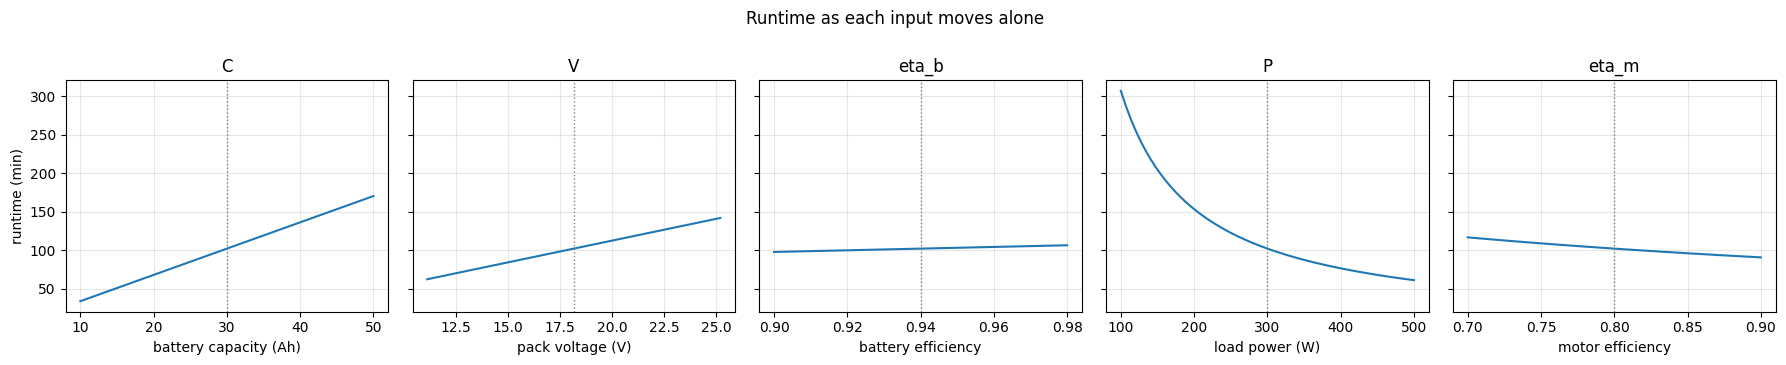

    C:   34.1 min at lower bound,  170.6 min at upper bound
    V:   62.6 min at lower bound,  142.1 min at upper bound
eta_b:   98.0 min at lower bound,  106.7 min at upper bound
    P:  307.1 min at lower bound,   61.4 min at upper bound
eta_m:  117.0 min at lower bound,   91.0 min at upper bound


In [2]:
fig, axes = plt.subplots(1, len(BOUNDS), figsize=(18, 3.6), sharey=True)
for ax, (name, (lo, hi)) in zip(axes, BOUNDS.items()):
    xs = np.linspace(lo, hi, 60)
    ax.plot(xs, [runtime(**{**MID, name: x}) for x in xs])
    ax.axvline(MID[name], color="grey", ls=":", lw=1)
    ax.set(xlabel=LABELS[name], title=name)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("runtime (min)")
fig.suptitle("Runtime as each input moves alone", y=1.0)
plt.tight_layout()
plt.show()

for name, (lo, hi) in BOUNDS.items():
    a, b = runtime(**{**MID, name: lo}), runtime(**{**MID, name: hi})
    print(f"{name:>5}: {a:6.1f} min at lower bound, {b:6.1f} min at upper bound")

## SSS motors: torque vs speed (first quadrant)

First quadrant means positive speed and positive torque, the motor driving the load. The numbers come from the SSS spec sheet (`SSS-Specs-2.pdf`, 12 pages, 27 motor models, 263 windings), typed into `sss_motors.csv` next to this notebook (27 motor models, 263 windings). The sheet lists no torque curve, so each line is built from three equations:

- `speed (rpm) = Kv * (V - I * R)`: the motor spins up until its back-voltage balances what is left after the resistive drop.
- `Kt = 60 / (2 * pi * Kv)`  (N*m per amp): the torque constant follows from `Kv`.
- `torque (N*m) = Kt * (I - I0)`: torque comes from the current beyond what the motor draws spinning freely.

**Why the line has a flat start.** At zero speed there is no back-voltage, so the full voltage across the tiny resistance `R` would push `V / R` amps (thousands, and tens of N*m). The sheet's max current stops that, so the torque is capped at `Kt * (I_max - I0)`. Each line therefore starts at rpm = 0 at that maximum torque and stays flat while the controller holds the current at `I_max`. It bends down once the voltage runs out (`V_max = I_max * R + back-voltage`, at the "corner" speed), then falls straight to zero torque at the no-load speed.

Every winding is drawn at its own rated voltage. Windings are named as on the sheet: `Y` or `D` (star or delta) after the turn count.

Assumptions: `R` is the sheet's resistance column taken as ohms. `I0` is the sheet's no-load current, measured at 11.1 V, held constant.

**Suspect resistance values.** Many resistance entries on the sheet look like typos with a digit dropped (for example 3656-V2 5Y lists 0.083 ohm, but its neighbour lists 0.013). A line is drawn *dotted* when its max current times its resistance is under 1% or over 30% of its max voltage, because that puts the corner speed in an implausible place. The sheet's value is used as printed. Only the corner speed depends on `R`; the flat torque and the no-load speed do not.

In [3]:
import csv
from pathlib import Path

CSV = next(p for p in (Path("sss_motors.csv"), Path("optimization/sss_motors.csv")) if p.exists())

# motor -> {"windings": [...], "p_cont", "p_max", "max_rpm"}, read from the spec sheet
MOTORS = {}
with open(CSV) as f:
    for r in csv.DictReader(f):
        m = MOTORS.setdefault(r["motor"], {"windings": [], "p_cont": float(r["p_cont_w"]),
                                          "p_max": float(r["p_max_w"]), "max_rpm": float(r["max_rpm"])})
        m["windings"].append(dict(name=r["winding"], Kv=float(r["kv_rpm_per_v"]), I_max=float(r["i_max_a"]),
                                  V_max=float(r["v_max_v"]), R=float(r["r_ohm"]), I0=float(r["i0_a_at_11v"])))


def curve(w):
    """(rpm, torque) corners of one winding's line, and whether its R looks like a typo."""
    Kt = 60 / (2 * np.pi * w["Kv"])
    T_max = Kt * (w["I_max"] - w["I0"])                  # torque at the current limit
    rpm_corner = w["Kv"] * (w["V_max"] - w["I_max"] * w["R"])  # speed where the voltage runs out
    rpm_free = w["Kv"] * (w["V_max"] - w["I0"] * w["R"])       # no-load speed
    drop = w["I_max"] * w["R"] / w["V_max"]
    return [0, rpm_corner, rpm_free], [T_max, T_max, 0], not 0.01 <= drop <= 0.30


### All 5Y windings on one graph, with the motors earlier PEP teams used

Every motor that has a 5Y winding, one line per motor, torque against speed. 5Y has a different Kv, voltage and current on each motor, which is why the lines differ. Set `WINDING` to look at another winding.

**Highlighted (thick, black outline, star in the legend):** SSS motors named in the PEP 2025 and 2026 white papers (`PEP2025TeamExtractions/`, `PEP2026TeamExtractions/`). Only three motor models appear:

| Motor | Teams | Winding the paper gives |
|---|---|---|
| 5684-V2 | Alabama 2025 and 2026 | 1050 Kv, 165 A, 45 V, which is the **5Y** winding |
| 56123-V2 | VCU 2025 and 2026; Illinois 2025 and 2026; Texas A&M 2026 | VCU: 500 Kv, which is the **6Y**. Illinois 2025 says 550 Kv and Texas A&M says 700 Kv, neither of which is a 56123-V2 winding on the sheet. Illinois 2026 gives no Kv. |
| 56154-V2 | Auburn 2025; East Carolina 2026 | none stated (Auburn says 25,000 rpm at 55.5 V) |

So only 5684-V2 is confirmed to have used its 5Y winding. For the other two the 5Y line shows the same motor, not necessarily the same winding. Other teams used non-SSS motors (for example NC State's TP5680 and Georgia's KingVal 4092) and are not drawn.

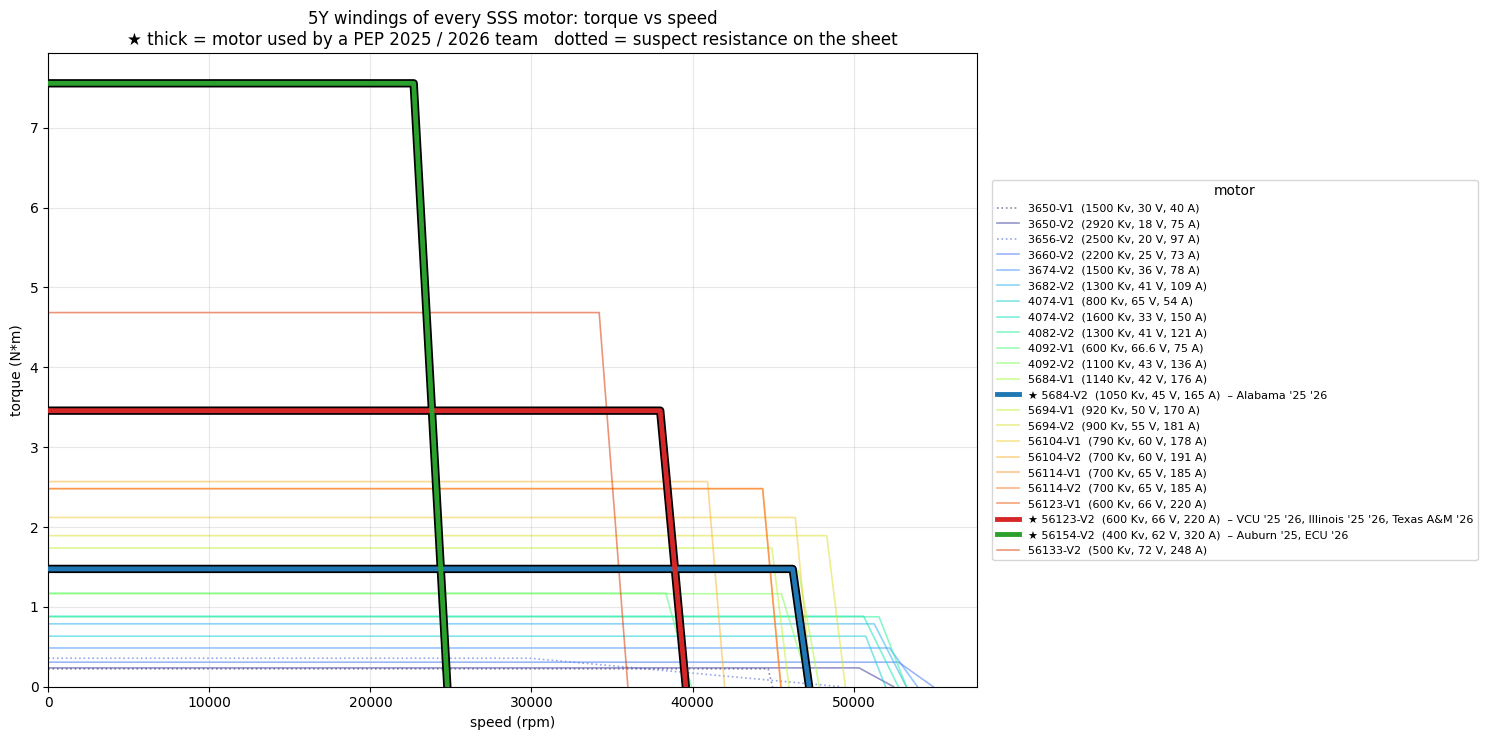

In [4]:
WINDING = "5Y"

# SSS motors named in the PEP 2025 / 2026 white papers -> teams that used them
USED_BY = {
    "SSS 5684-V2": "Alabama '25 '26",
    "SSS 56123-V2": "VCU '25 '26, Illinois '25 '26, Texas A&M '26",
    "SSS 56154-V2": "Auburn '25, ECU '26",
}

picked = [(motor, w) for motor, d in MOTORS.items() for w in d["windings"] if w["name"] == WINDING]
others = iter(plt.cm.turbo(np.linspace(0.02, 0.98, len(picked))))
USED_COLOR = {"SSS 5684-V2": "tab:blue", "SSS 56123-V2": "tab:red", "SSS 56154-V2": "tab:green"}

fig, ax = plt.subplots(figsize=(15, 7.5))
for motor, w in picked:
    rpm, torque, suspect = curve(w)
    used = motor in USED_BY
    color = USED_COLOR[motor] if used else next(others)
    label = f"{motor.replace('SSS ', '')}  ({w['Kv']:g} Kv, {w['V_max']:g} V, {w['I_max']:g} A)"
    if used:
        ax.plot(rpm, torque, color="black", lw=6, solid_capstyle="round", zorder=2)
        label = f"★ {label}  – {USED_BY[motor]}"
    ax.plot(rpm, torque, color=color, lw=3.5 if used else 1.2, alpha=1 if used else 0.55,
            ls=":" if suspect else "-", label=label, zorder=3 if used else 1)
ax.set(xlabel="speed (rpm)", ylabel="torque (N*m)", xlim=(0, None), ylim=(0, None),
       title=f"{WINDING} windings of every SSS motor: torque vs speed\n"
             f"★ thick = motor used by a PEP 2025 / 2026 team   dotted = suspect resistance on the sheet")
ax.grid(alpha=0.3)
ax.legend(title="motor", fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

## Propeller torque

One more equation, the standard propeller load law:

`Torque (N*m) = K_Q * rho * n^2 * D^5`

with `n` the rotation rate in revolutions per **second** (`rpm / 60`) and `D` the diameter in metres. Torque grows with
the square of speed and the **fifth power of diameter** - spin a propeller twice as fast and it asks for four times the
torque; make it a third bigger and it asks for four times the torque at the same speed.

| Symbol | Meaning | Unit |
|---|---|---|
| `K_Q` | torque coefficient of the propeller (shape, pitch, loading) | - |
| `rho` | water density (fresh, fixed at 999) | kg/m^3 |
| `n` | rotation rate | rev/s |
| `D` | propeller diameter | m (entered in inches below) |

`K_Q` is the one honest unknown: it depends on the blade shape and pitch and really comes from a propeller chart or test.
The bounds below span typical model-boat props. Sanity check against the full model in `explore.ipynb`: its baseline asks
5.3 N*m at 2640 rpm from a 6 in propeller, which this equation reproduces with `K_Q = 0.033` - inside the range.

In [5]:
RHO = 999.0  # fresh water, kg/m^3

# (lower, upper) for every propeller input. Edit these.
PROP_BOUNDS = {
    "K_Q":  (0.02, 0.05),      # torque coefficient
    "D_in": (2.0, 5.0),        # diameter, inches
    "rpm":  (1000.0, 5000.0),  # shaft speed
}
PROP_LABELS = {"K_Q": "torque coefficient K_Q", "D_in": "diameter (in)", "rpm": "shaft speed (rpm)"}
PROP_MID = {k: (lo + hi) / 2 for k, (lo, hi) in PROP_BOUNDS.items()}


def prop_torque(K_Q, D_in, rpm):
    """Propeller torque in N*m."""
    return K_Q * RHO * (rpm / 60) ** 2 * (D_in * 0.0254) ** 5


print("All propeller inputs at the midpoint of their bounds:")
for k, v in PROP_MID.items():
    print(f"  {k:>5} = {v:g}")
print(f"\nPropeller torque {prop_torque(**PROP_MID):.1f} N*m")

All propeller inputs at the midpoint of their bounds:
    K_Q = 0.035
   D_in = 3.5
    rpm = 3000

Propeller torque 0.5 N*m


### Sweep each propeller input on its own

Same idea as the runtime sweeps: hold the others at their midpoint, move one across its bounds.

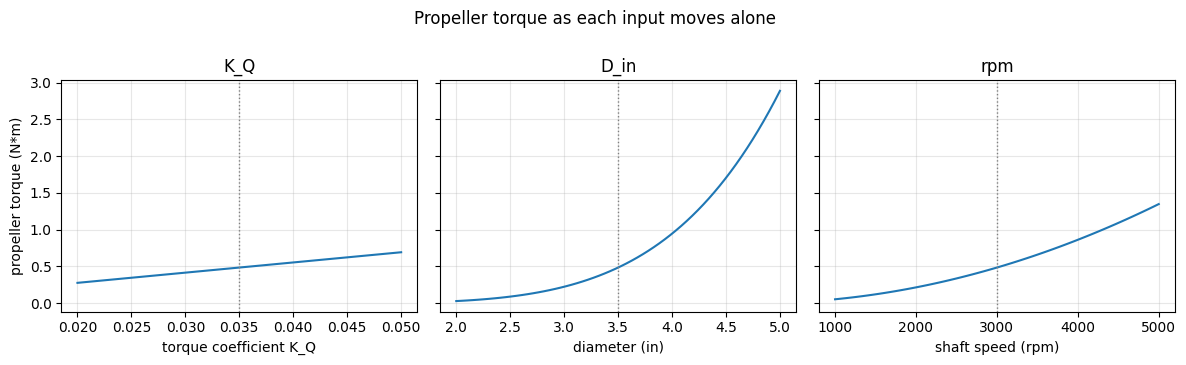

  K_Q:    0.3 N*m at lower bound,    0.7 N*m at upper bound
 D_in:    0.0 N*m at lower bound,    2.9 N*m at upper bound
  rpm:    0.1 N*m at lower bound,    1.3 N*m at upper bound


In [6]:
fig, axes = plt.subplots(1, len(PROP_BOUNDS), figsize=(12, 3.6), sharey=True)
for ax, (name, (lo, hi)) in zip(axes, PROP_BOUNDS.items()):
    xs = np.linspace(lo, hi, 60)
    ax.plot(xs, [prop_torque(**{**PROP_MID, name: x}) for x in xs])
    ax.axvline(PROP_MID[name], color="grey", ls=":", lw=1)
    ax.set(xlabel=PROP_LABELS[name], title=name)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("propeller torque (N*m)")
fig.suptitle("Propeller torque as each input moves alone", y=1.0)
plt.tight_layout()
plt.show()

for name, (lo, hi) in PROP_BOUNDS.items():
    a, b = prop_torque(**{**PROP_MID, name: lo}), prop_torque(**{**PROP_MID, name: hi})
    print(f"{name:>5}: {a:6.1f} N*m at lower bound, {b:6.1f} N*m at upper bound")

### The load curve on the motor chart: where they cross is the operating point

The motor lines from the chart above say what torque each winding *can* deliver at each speed. The propeller curve says
what torque the load *demands* at each speed. A motor driving this propeller settles where the two cross - it cannot spin
faster, because past the crossing the propeller asks for more torque than the motor has.

The chart overlays the propeller curve (at the midpoint `K_Q` and diameter; edit `PROP_MID` above) on the same 5Y motor
lines, zoomed to the speeds where the crossings happen. The table then reports every 5Y winding's operating point -
speed, torque and shaft power `Q * 2 pi n` - and compares that power with the motor's continuous rating from the sheet:
a winding marked `OVER` would be running its motor beyond its continuous rating just to hold this propeller's load.

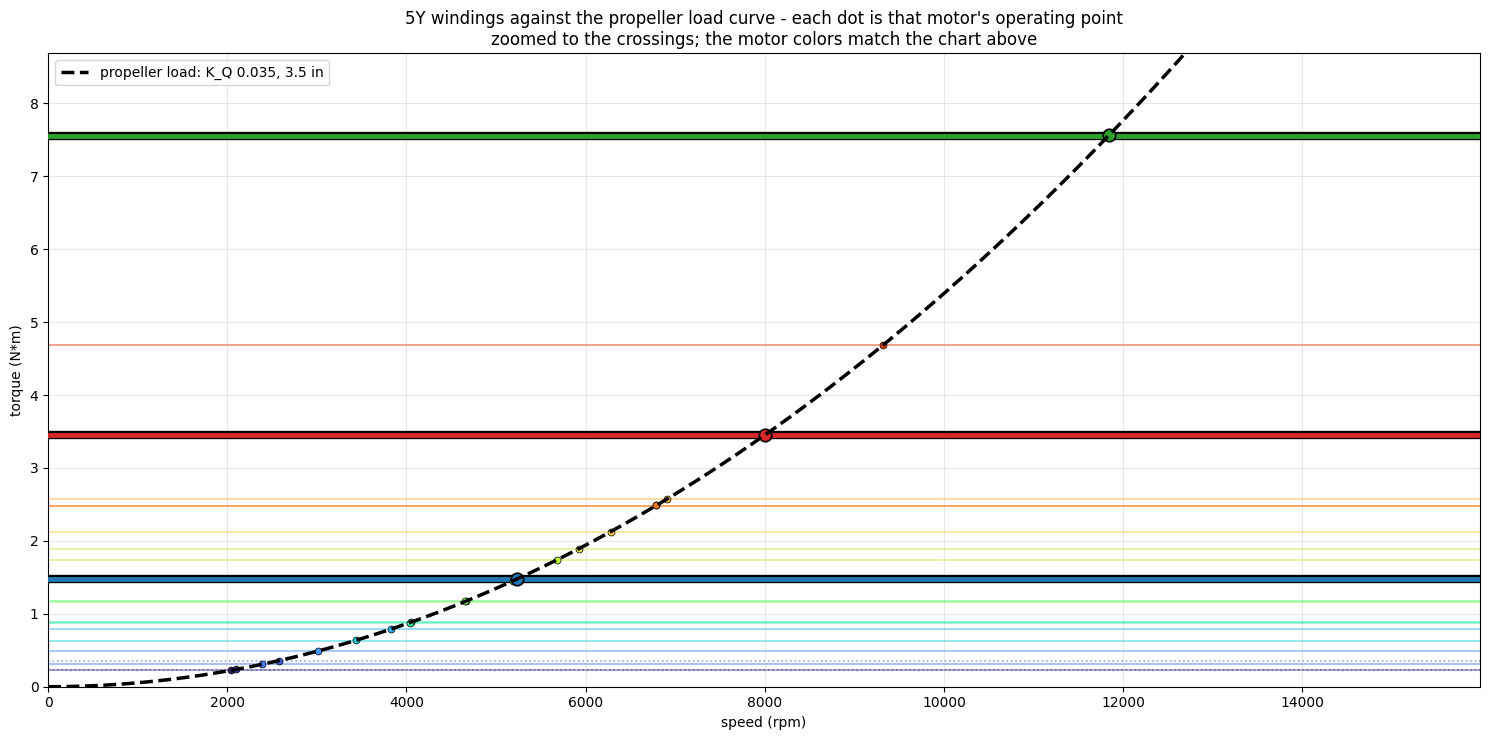

motor           op rpm    N*m  shaft W  cont W   vs continuous rating
*56154-V2        11840   7.56     9374   14000   67%
 56133-V2         9321   4.69     4574   12000   38%
 56123-V1         8007   3.46     2899    9000   32%
*56123-V2         8007   3.46     2899    9500   31%
 56104-V2         6908   2.57     1862    6800   27%
 56114-V1         6790   2.49     1768    7000   25%
 56114-V2         6790   2.49     1768    7800   23%
 56104-V1         6280   2.13     1399    6000   23%
 5694-V2          5927   1.89     1176    6000   20%
 5694-V1          5680   1.74     1035    5000   21%
*5684-V2          5232   1.48      809    4500   18%
 5684-V1          5194   1.45      791    4000   20%
 4092-V1          4663   1.17      573    2500   23%
 4092-V2          4658   1.17      571    3000   19%
 4074-V2          4051   0.89      375    1600   23%
 4082-V2          4037   0.88      371    2400   15%
 3682-V2          3823   0.79      316    2000   16%
 4074-V1          3431   0.63

In [7]:
def operating_point(w, K_Q=None, D_in=None):
    """Where this winding's torque line crosses the propeller load curve: (rpm, N*m)."""
    K_Q = PROP_MID["K_Q"] if K_Q is None else K_Q
    D_in = PROP_MID["D_in"] if D_in is None else D_in
    rpm_line, torque_line, _ = curve(w)
    rpms = np.linspace(0, rpm_line[-1], 4000)
    gap = np.interp(rpms, rpm_line, torque_line) - prop_torque(K_Q, D_in, rpms)
    k = np.argmax(gap < 0)                      # first speed where the prop asks more than the motor has
    return (rpms[k], prop_torque(K_Q, D_in, rpms[k])) if k > 0 else (0.0, 0.0)


others = iter(plt.cm.turbo(np.linspace(0.02, 0.98, len(picked))))
fig, ax = plt.subplots(figsize=(15, 7.5))
top_rpm = 1.35 * max(operating_point(w)[0] for _, w in picked)
for motor, w in picked:
    rpm, torque, suspect = curve(w)
    used = motor in USED_BY
    color = USED_COLOR[motor] if used else next(others)
    if used:
        ax.plot(rpm, torque, color="black", lw=6, solid_capstyle="round", zorder=2)
    ax.plot(rpm, torque, color=color, lw=3.5 if used else 1.2, alpha=1 if used else 0.55,
            ls=":" if suspect else "-", zorder=3 if used else 1)
    r_op, q_op = operating_point(w)
    ax.plot(r_op, q_op, "o", ms=9 if used else 5, color=color, mec="black", mew=1.2 if used else 0.5, zorder=4)
rpms = np.linspace(0, top_rpm, 300)
ax.plot(rpms, prop_torque(PROP_MID["K_Q"], PROP_MID["D_in"], rpms), color="black", lw=2.5, ls="--",
        label=f"propeller load: K_Q {PROP_MID['K_Q']:g}, {PROP_MID['D_in']:g} in", zorder=5)
q_top = 1.15 * max(curve(w)[1][0] for _, w in picked)
ax.set(xlabel="speed (rpm)", ylabel="torque (N*m)", xlim=(0, top_rpm), ylim=(0, q_top),
       title=f"{WINDING} windings against the propeller load curve - each dot is that motor's operating point\n"
             f"zoomed to the crossings; the motor colors match the chart above")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"{'motor':<14}{'op rpm':>8}{'N*m':>7}{'shaft W':>9}{'cont W':>8}   vs continuous rating")
for motor, w in sorted(picked, key=lambda t: -operating_point(t[1])[0]):
    r_op, q_op = operating_point(w)
    p_op = q_op * 2 * np.pi * r_op / 60
    p_cont = MOTORS[motor]["p_cont"]
    flag = "OVER" if p_op > p_cont else f"{100 * p_op / p_cont:.0f}%"
    star = "*" if motor in USED_BY else " "
    print(f"{star}{motor.replace('SSS ', ''):<13}{r_op:>8.0f}{q_op:>7.2f}{p_op:>9.0f}{p_cont:>8.0f}   {flag}")

## Speed: one equation

`Speed (mph) = rpm * pitch (in) * slip / 1056`

A propeller of pitch `p` screws itself forward `p` inches per turn; slip is the fraction of that it actually
achieves. For now **rpm is just an input** - whatever the motor ends up turning - and **all the hull physics
hides inside `slip`** (a draggy boat is a lower slip factor). Nothing else. Later the motor-propeller crossing
from the chart above can pick the rpm, and drag, planing and cavitation can come back as constraints on top -
one piece at a time, once each simpler picture makes sense.

| Symbol | Meaning | Unit |
|---|---|---|
| `rpm` | propeller shaft speed | rev/min |
| `pitch_in` | propeller pitch | in |
| `slip` | advance per turn actually achieved | - |

In [8]:
# (lower, upper) for every input of the speed equation. Edit these.
SPEED_BOUNDS = {
    "rpm":      (1000.0, 6000.0),
    "pitch_in": (6.0, 14.0),      # in
    "slip":     (0.75, 0.95),
}
SPEED_LABELS = {"rpm": "shaft speed (rpm)", "pitch_in": "pitch (in)", "slip": "slip factor"}
SPEED_MID = {k: (lo + hi) / 2 for k, (lo, hi) in SPEED_BOUNDS.items()}


def speed_mph(rpm, pitch_in, slip):
    """Boat speed in mph: pitch inches per turn, minus slip."""
    return rpm * pitch_in * slip / 1056


print("All inputs at the midpoint of their bounds:")
for k, v in SPEED_MID.items():
    print(f"  {k:>9} = {v:g}")
print(f"\nSpeed {speed_mph(**SPEED_MID):.1f} mph")

All inputs at the midpoint of their bounds:
        rpm = 3500
   pitch_in = 10
       slip = 0.85

Speed 28.2 mph


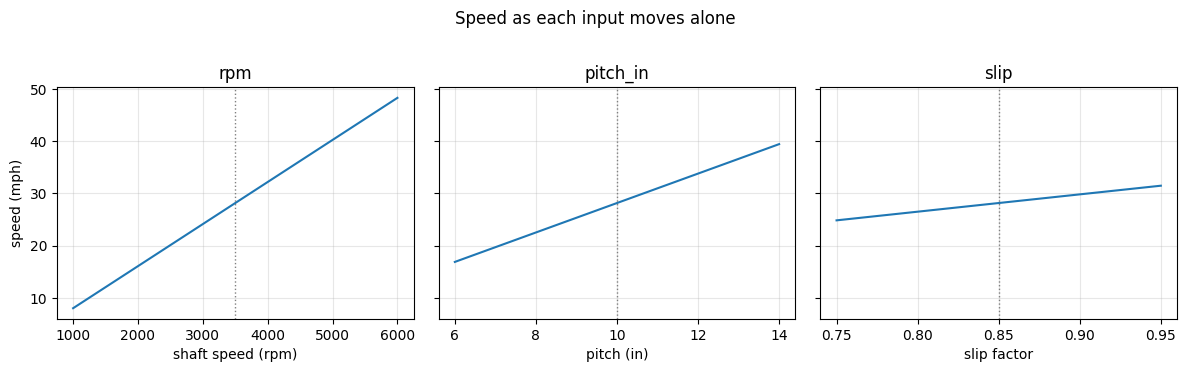

      rpm:   8.0 mph at lower bound,  48.3 mph at upper bound
 pitch_in:  16.9 mph at lower bound,  39.4 mph at upper bound
     slip:  24.9 mph at lower bound,  31.5 mph at upper bound


In [9]:
fig, axes = plt.subplots(1, len(SPEED_BOUNDS), figsize=(12, 3.6), sharey=True)
for ax, (name, (lo, hi)) in zip(axes, SPEED_BOUNDS.items()):
    xs = np.linspace(lo, hi, 60)
    ax.plot(xs, [speed_mph(**{**SPEED_MID, name: x}) for x in xs])
    ax.axvline(SPEED_MID[name], color="grey", ls=":", lw=1)
    ax.set(xlabel=SPEED_LABELS[name], title=name)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("speed (mph)")
fig.suptitle("Speed as each input moves alone", y=1.02)
plt.tight_layout()
plt.show()

for name, (lo, hi) in SPEED_BOUNDS.items():
    a, b = speed_mph(**{**SPEED_MID, name: lo}), speed_mph(**{**SPEED_MID, name: hi})
    print(f"{name:>9}: {a:5.1f} mph at lower bound, {b:5.1f} mph at upper bound")